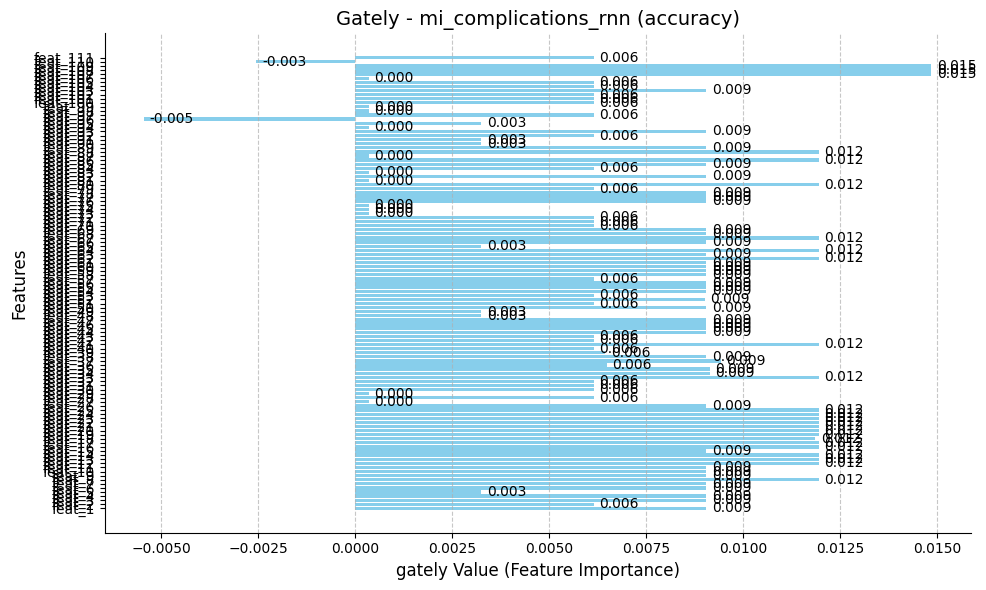

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import logging
import sys, os

# Add the parent directory (project_root) to sys.path
PARENT_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if PARENT_DIR not in sys.path:
    sys.path.append(PARENT_DIR)


from scipy.stats import spearmanr, pearsonr
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, mean_squared_error,
    r2_score, mean_absolute_error
)

from cgt_xai.concepts.gately_point import exact_gately_value
from cgt_xai.models import get_model
from cgt_xai.utils.plotting import plot_single_valuation

# Logging

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

# Config

DATASETS = ["mi_complications"]   # UCI datasets
MODEL_NAMES = ["rnn"]  # adjust names to match get_model()
SCORING = "accuracy"
RANDOM_STATE = 42

BASE_OUTPUT_DIR = Path("./output_rnn/feature_valuation_uci")
BASE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Dataset loaders for UCI Lung Cancer and MI Complications

def load_lung_cancer():
    """
    UCI Lung Cancer dataset:
    - File: lung-cancer.data
    - First column: class label (1,2,3)
    - Rest: features (some '?')
    """
    path = "../../datasets/lung-cancer.data"
    df = pd.read_csv(path, header=None, na_values="?")

    # target
    y = df.iloc[:, 0].astype(int).values

    # features
    X_df = df.iloc[:, 1:]
    feature_names = [f"attr_{i}" for i in range(1, X_df.shape[1] + 1)]

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.3,
        stratify=y,
        random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_mi_complications(binary_let_is=True):
    """
    UCI Myocardial Infarction Complications dataset:
    - File: MI.data
    - We'll treat LET_IS (col 123) as binary death outcome (dead vs alive).
    - Features: columns 1..111
    """
    path = "../../datasets/MI.data"
    df = pd.read_csv(path, header=None, na_values="?")

    # features: columns 1..111
    X_df = df.iloc[:, 1:112]
    feature_names = [f"feat_{i}" for i in range(1, X_df.shape[1] + 1)]

    # LET_IS at column 123: 0 = alive, 1..7 = different death categories
    let_is = df.iloc[:, 123].astype(int).values

    if binary_let_is:
        y = (let_is != 0).astype(int)
    else:
        y = let_is  # multi-class (0..7)

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        stratify=y,
        random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_dataset(name: str):
    if name == "lung_cancer":
        return load_lung_cancer()
    elif name == "mi_complications":
        return load_mi_complications(binary_let_is=True)
    else:
        raise ValueError(f"Unknown dataset name: {name}")

# Utility + scorer

class DataWrapper:
    def __init__(self, indices, names=None):
        self.indices = indices
        self.data_names = names if names is not None else [f"f{i}" for i in range(len(indices))]

    def __len__(self):
        return len(self.indices)

    def __iter__(self):
        return iter(self.indices)


class Utility:
    def __init__(self, X_train, y_train, X_test, y_test, model_name, scorer,
                 feature_names=None, random_state=42):
        self.X_train = X_train
        self.y_train = y_train
        self.X_test = X_test
        self.y_test = y_test
        self.model_name = model_name
        self.scorer = scorer
        self.data = DataWrapper(list(range(X_train.shape[1])), feature_names)
        self.random_state = random_state
        self._cache = {}

    def __call__(self, subset):
        key = tuple(sorted(subset))
        if key in self._cache:
            return self._cache[key]

        if len(key) == 0:
            # majority-class baseline
            majority = np.bincount(self.y_train.astype(int)).argmax()
            y_pred = np.full_like(self.y_test, majority)
            score = self.scorer(self.y_test, y_pred)
            self._cache[key] = score
            return score

        model = get_model(self.model_name, self.random_state)
        model.fit(self.X_train[:, key], self.y_train)
        y_pred = model.predict(self.X_test[:, key])
        score = self.scorer(self.y_test, y_pred)
        self._cache[key] = score
        return score


def get_scorer(name):
    if name == "accuracy":
        return lambda y_true, y_pred: accuracy_score(y_true, y_pred)
    elif name == "f1_macro":
        return lambda y_true, y_pred: f1_score(y_true, y_pred, average="macro")
    elif name == "r2":
        return lambda y_true, y_pred: r2_score(y_true, y_pred)
    elif name == "mse":
        return lambda y_true, y_pred: -mean_squared_error(y_true, y_pred)
    elif name == "rmse":
        return lambda y_true, y_pred: -np.sqrt(mean_squared_error(y_true, y_pred))
    elif name == "mae":
        return lambda y_true, y_pred: -mean_absolute_error(y_true, y_pred)
    else:
        raise ValueError(f"Unknown scorer: {name}")

# Main

def main():
    scorer = get_scorer(SCORING)

    for dataset_name in DATASETS:
        X_train, X_test, y_train, y_test, feature_names = load_dataset(dataset_name)

        for model_name in MODEL_NAMES:
            logger.info("\n" + "="*70)
            logger.info(f"DATASET: {dataset_name} | MODEL: {model_name}")
            logger.info("="*70)

            OUTPUT_DIR = BASE_OUTPUT_DIR / f"{dataset_name}_{model_name}_results"
            OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

            utility = Utility(
                X_train, y_train, X_test, y_test,
                model_name=model_name,
                scorer=scorer,
                feature_names=feature_names,
                random_state=RANDOM_STATE
            )

            n_features = X_train.shape[1]
            all_features_set = set(range(n_features))
            v_N = utility(list(all_features_set))
            logger.info(f"  v(N) with all features ({SCORING}) = {v_N:.4f}")

            # 1) Gately feature attributions (EXACT)
            logger.info("Computing EXACT Gately values...")
            gately_result = exact_gately_value(utility, options=None, progress=False)
            gately_vals = gately_result.values

            df_vals = pd.DataFrame({
                "method": "gately",
                "feature": feature_names,
                "value": gately_vals
            })
            vals_csv_path = OUTPUT_DIR / f"{dataset_name}_{model_name}_feature_valuations_gately.csv"
            df_vals.to_csv(vals_csv_path, index=False)
            logger.info(f"  Saved Gately valuations to: {vals_csv_path}")

            try:
                plot_single_valuation(
                    gately_vals,
                    feature_names,
                    method_name="gately",
                    title=f"Gately - {dataset_name}_{model_name} ({SCORING})",
                    output_path=OUTPUT_DIR / f"{dataset_name}_{model_name}_gately.png"
                )
            except Exception as e:
                logger.warning(f"  Could not plot Gately for {dataset_name}, {model_name}: {e}")

            results = {"gately": gately_vals}

            # 2) Global sensitivity (leave-one-out impact)
            logger.info("\nCalculating Global Sensitivity (Leave-One-Out Impact)...")

            global_impacts = []
            for i in range(n_features):
                features_except_i = list(all_features_set - {i})
                v_N_minus_i = utility(features_except_i)
                impact = v_N - v_N_minus_i
                global_impacts.append(impact)
                logger.info(f"  Impact of removing '{feature_names[i]}': {impact:.4f}")

            global_impact_vector = np.array(global_impacts)

            sensitivity_results = []
            for method_name, attribution_values in results.items():
                corr_spearman, p_spearman = spearmanr(attribution_values, global_impact_vector)
                corr_pearson, p_pearson = pearsonr(attribution_values, global_impact_vector)

                cos_sim = np.dot(attribution_values, global_impact_vector) / (
                    (np.linalg.norm(attribution_values) * np.linalg.norm(global_impact_vector)) + 1e-10
                )

                sensitivity_results.append({
                    "method": method_name,
                    "sensitivity_spearman": corr_spearman,
                    "p_value_spearman": p_spearman,
                    "sensitivity_pearson": corr_pearson,
                    "p_value_pearson": p_pearson,
                    "cosine_similarity": cos_sim
                })

                logger.info(f"  {method_name}: Spearman={corr_spearman:.4f}, "
                            f"Pearson={corr_pearson:.4f}, Cosine={cos_sim:.4f}")

            sensitivity_df = pd.DataFrame(sensitivity_results)
            logger.info("\nGLOBAL SENSITIVITY (FAITHFULNESS) METRICS")
            logger.info(sensitivity_df.to_string(index=False))

            sens_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_global_sensitivity_gately.csv"
            sensitivity_df.to_csv(sens_csv, index=False)
            logger.info(f"  Saved global sensitivity to: {sens_csv}")

            # 3) Global robustness (noise stability) - recompute Gately
            logger.info("\nEvaluating robustness under input noise...")
            noise_level = 0.05
            noise = np.random.normal(
                0,
                noise_level * X_train.std(axis=0),
                X_train.shape
            )
            X_train_noisy = X_train + noise

            utility_noisy = Utility(
                X_train_noisy, y_train, X_test, y_test,
                model_name=model_name,
                scorer=scorer,
                feature_names=feature_names,
                random_state=RANDOM_STATE
            )

            gately_noisy_result = exact_gately_value(utility_noisy, options=None, progress=False)
            gately_vals_noisy = gately_noisy_result.values
            noisy_results = {"gately": gately_vals_noisy}

            robustness_results = []
            for method_name in results.keys():
                phi_original = results[method_name]
                phi_noisy = noisy_results[method_name]

                cos_sim = np.dot(phi_original, phi_noisy) / (
                    (np.linalg.norm(phi_original) * np.linalg.norm(phi_noisy)) + 1e-10
                )

                l2_dist = np.linalg.norm(phi_original - phi_noisy)
                l2_norm = l2_dist / (np.linalg.norm(phi_original) + 1e-10)

                rank_corr, _ = spearmanr(phi_original, phi_noisy)

                robustness_results.append({
                    "method": method_name,
                    "cosine_similarity": cos_sim,
                    "rank_correlation": rank_corr,
                    "normalized_l2_distance": l2_norm
                })

                logger.info(f"  {method_name}: Cosine={cos_sim:.4f}, "
                            f"RankCorr={rank_corr:.4f}, L2={l2_norm:.4f}")

            robustness_df = pd.DataFrame(robustness_results)
            logger.info("\n" + "="*70)
            logger.info("GLOBAL ROBUSTNESS (STABILITY) METRICS")
            logger.info("="*70)
            logger.info(robustness_df.to_string(index=False))

            rob_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_global_robustness_gately.csv"
            robustness_df.to_csv(rob_csv, index=False)
            logger.info(f"  Saved global robustness to: {rob_csv}")

            # 4) Combined faithfulness figure (3 panels)
            fig, axes = plt.subplots(1, 3, figsize=(18, 6))

            # Panel 1: sensitivity (Spearman)
            ax1 = axes[0]
            methods = sensitivity_df["method"]
            sens_scores = sensitivity_df["sensitivity_spearman"]
            colors = ['steelblue' if x > 0.5 else 'coral' for x in sens_scores]

            ax1.barh(methods, sens_scores, color=colors)
            ax1.set_xlabel("Spearman Correlation", fontsize=12)
            ax1.set_title("Global Sensitivity\n(Attribution ↔ Leave-One-Out Impact)",
                          fontsize=14, fontweight='bold')
            ax1.axvline(0, color='red', linestyle='--', linewidth=1, label='No correlation')
            ax1.axvline(0.7, color='green', linestyle='--', linewidth=1,
                        alpha=0.5, label='Strong correlation')
            ax1.grid(axis='x', alpha=0.3)
            ax1.legend(fontsize=9)

            # Panel 2: sensitivity alignment (cosine)
            ax2 = axes[1]
            cos_scores = sensitivity_df["cosine_similarity"]
            colors2 = ['darkgreen' if x > 0.7 else 'orange' for x in cos_scores]

            ax2.barh(methods, cos_scores, color=colors2)
            ax2.set_xlabel("Cosine Similarity", fontsize=12)
            ax2.set_title("Attribution Alignment\n(Cosine Similarity)",
                          fontsize=14, fontweight='bold')
            ax2.axvline(1.0, color='green', linestyle='--', linewidth=1,
                        label='Perfect alignment')
            ax2.grid(axis='x', alpha=0.3)
            ax2.legend(fontsize=9)

            # Panel 3: robustness (cosine original vs noisy)
            ax3 = axes[2]
            rob_scores = robustness_df["cosine_similarity"]
            colors3 = ['purple' if x > 0.9 else 'salmon' for x in rob_scores]

            ax3.barh(robustness_df["method"], rob_scores, color=colors3)
            ax3.set_xlabel("Cosine Similarity (Original ↔ Noisy)", fontsize=12)
            ax3.set_title("Global Robustness\n(Stability Under Noise)",
                          fontsize=14, fontweight='bold')
            ax3.axvline(1.0, color='green', linestyle='--', linewidth=1,
                        label='Perfect stability')
            ax3.axvline(0.9, color='orange', linestyle='--', linewidth=1,
                        alpha=0.5, label='Good stability')
            ax3.grid(axis='x', alpha=0.3)
            ax3.legend(fontsize=9)

            plt.tight_layout()
            fig_path = OUTPUT_DIR / f"{dataset_name}_{model_name}_global_faithfulness_gately.png"
            plt.savefig(fig_path, dpi=300, bbox_inches='tight')
            plt.close(fig)

            logger.info(f"\nAll faithfulness results saved to: {OUTPUT_DIR}")
            logger.info("="*70)

if __name__ == "__main__":
    main()

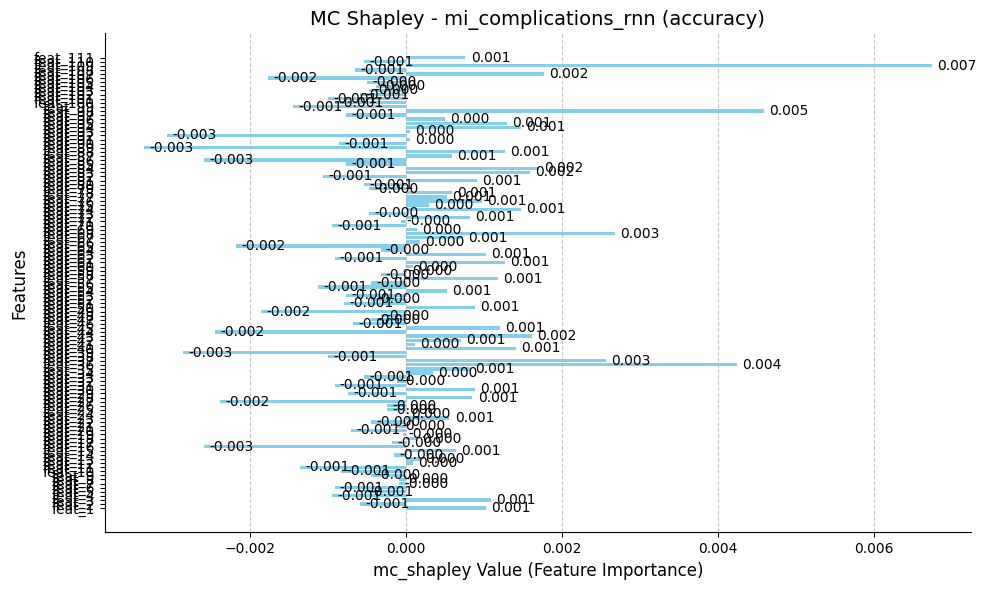

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import logging
import sys, os

# Add the parent directory (project_root) to sys.path
PARENT_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if PARENT_DIR not in sys.path:
    sys.path.append(PARENT_DIR)

from scipy.stats import spearmanr, pearsonr
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, mean_squared_error,
    r2_score, mean_absolute_error
)

from cgt_xai.concepts.shapley import montecarlo_shapley_value
from cgt_xai.models import get_model
from cgt_xai.utils.plotting import plot_single_valuation

# Logging

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

# Config

DATASETS = ["mi_complications"]   #UCI datasets
MODEL_NAMES = ["rnn"]          # adjust names to match get_model()
SCORING = "accuracy"
N_MC_ITERATIONS = 100
RANDOM_STATE = 42

BASE_OUTPUT_DIR = Path("./output/feature_valuation_uci")
BASE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# Dataset loaders for UCI Lung Cancer and MI Complications

def load_lung_cancer():
    """
    UCI Lung Cancer dataset:
    - File: lung-cancer.data
    - First column: class label (1,2,3)
    - Rest: features (some '?')
    """
    path = "../../datasets/lung-cancer.data"
    df = pd.read_csv(path, header=None, na_values="?")

    # target
    y = df.iloc[:, 0].astype(int).values

    # features
    X_df = df.iloc[:, 1:]
    feature_names = [f"attr_{i}" for i in range(1, X_df.shape[1] + 1)]

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.3,
        stratify=y,
        random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_mi_complications(binary_let_is=True):
    """
    UCI Myocardial Infarction Complications dataset:
    - File: MI.data
    - We'll treat LET_IS (col 123) as binary death outcome (dead vs alive).
    - Features: columns 1..111
    """
    path = "../../datasets/MI.data"
    df = pd.read_csv(path, header=None, na_values="?")

    # features: columns 1..111
    X_df = df.iloc[:, 1:112]
    feature_names = [f"feat_{i}" for i in range(1, X_df.shape[1] + 1)]

    # LET_IS at column 123: 0 = alive, 1..7 = different death categories
    let_is = df.iloc[:, 123].astype(int).values

    if binary_let_is:
        y = (let_is != 0).astype(int)
    else:
        y = let_is  # multi-class (0..7)

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        stratify=y,
        random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_dataset(name: str):
    if name == "lung_cancer":
        return load_lung_cancer()
    elif name == "mi_complications":
        return load_mi_complications(binary_let_is=True)
    else:
        raise ValueError(f"Unknown dataset name: {name}")


class DataWrapper:
    def __init__(self, indices, names=None):
        self.indices = indices
        self.data_names = names if names is not None else [f"f{i}" for i in range(len(indices))]

    def __len__(self):
        return len(self.indices)

    def __iter__(self):
        return iter(self.indices)


class Utility:
    def __init__(self, X_train, y_train, X_test, y_test, model_name, scorer,
                 feature_names=None, random_state=42):
        self.X_train = X_train
        self.y_train = y_train
        self.X_test = X_test
        self.y_test = y_test
        self.model_name = model_name
        self.scorer = scorer
        self.data = DataWrapper(list(range(X_train.shape[1])), feature_names)
        self.random_state = random_state
        self._cache = {}

    def __call__(self, subset):
        key = tuple(sorted(subset))
        if key in self._cache:
            return self._cache[key]

        if len(key) == 0:
            # majority-class baseline
            majority = np.bincount(self.y_train.astype(int)).argmax()
            y_pred = np.full_like(self.y_test, majority)
            score = self.scorer(self.y_test, y_pred)
            self._cache[key] = score
            return score

        model = get_model(self.model_name, self.random_state)
        model.fit(self.X_train[:, key], self.y_train)
        y_pred = model.predict(self.X_test[:, key])
        score = self.scorer(self.y_test, y_pred)
        self._cache[key] = score
        return score


def get_scorer(name):
    if name == "accuracy":
        return lambda y_true, y_pred: accuracy_score(y_true, y_pred)
    elif name == "f1_macro":
        return lambda y_true, y_pred: f1_score(y_true, y_pred, average="macro")
    elif name == "r2":
        return lambda y_true, y_pred: r2_score(y_true, y_pred)
    elif name == "mse":
        return lambda y_true, y_pred: -mean_squared_error(y_true, y_pred)
    elif name == "rmse":
        return lambda y_true, y_pred: -np.sqrt(mean_squared_error(y_true, y_pred))
    elif name == "mae":
        return lambda y_true, y_pred: -mean_absolute_error(y_true, y_pred)
    else:
        raise ValueError(f"Unknown scorer: {name}")


# Main: do "all the things" for each dataset + model

def main():
    scorer = get_scorer(SCORING)

    for dataset_name in DATASETS:
        X_train, X_test, y_train, y_test, feature_names = load_dataset(dataset_name)

        for model_name in MODEL_NAMES:
            logger.info("\n" + "="*70)
            logger.info(f"DATASET: {dataset_name} | MODEL: {model_name}")
            logger.info("="*70)

            OUTPUT_DIR = BASE_OUTPUT_DIR / f"{dataset_name}_{model_name}_results"
            OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

            utility = Utility(
                X_train, y_train, X_test, y_test,
                model_name=model_name,
                scorer=scorer,
                feature_names=feature_names,
                random_state=RANDOM_STATE
            )

            n_features = X_train.shape[1]
            all_features_set = set(range(n_features))
            v_N = utility(list(all_features_set))
            logger.info(f"  v(N) with all features ({SCORING}) = {v_N:.4f}")

            # 1. MC Shapley feature attributions (NO exact)
            logger.info("Computing Monte Carlo Shapley values...")
            shapley_result = montecarlo_shapley_value(
                utility,
                n_iterations=N_MC_ITERATIONS,
                options=None,
                progress=False
            )
            shapley_vals = shapley_result.values

            # Save per-feature values
            df_vals = pd.DataFrame({
                "method": "mc_shapley",
                "feature": feature_names,
                "value": shapley_vals
            })
            vals_csv_path = OUTPUT_DIR / f"{dataset_name}_{model_name}_feature_valuations_mc_shapley.csv"
            df_vals.to_csv(vals_csv_path, index=False)
            logger.info(f"  Saved MC Shapley valuations to: {vals_csv_path}")

            # Optional: bar plot
            try:
                plot_single_valuation(
                    shapley_vals,
                    feature_names,
                    method_name="mc_shapley",
                    title=f"MC Shapley - {dataset_name}_{model_name} ({SCORING})",
                    output_path=OUTPUT_DIR / f"{dataset_name}_{model_name}_mc_shapley.png"
                )
            except Exception as e:
                logger.warning(f"  Could not plot MC Shapley for {dataset_name}, {model_name}: {e}")

            results = {"mc_shapley": shapley_vals}

            # 2. Global sensitivity (leave-one-out impact)
            logger.info("\nCalculating Global Sensitivity (Leave-One-Out Impact)...")

            global_impacts = []
            for i in range(n_features):
                features_except_i = list(all_features_set - {i})
                v_N_minus_i = utility(features_except_i)
                impact = v_N - v_N_minus_i
                global_impacts.append(impact)
                logger.info(f"  Impact of removing '{feature_names[i]}': {impact:.4f}")

            global_impact_vector = np.array(global_impacts)

            sensitivity_results = []
            for method_name, attribution_values in results.items():
                if attribution_values is None:
                    logger.warning(f"  Skipping {method_name} (None values)")
                    continue

                corr_spearman, p_spearman = spearmanr(attribution_values, global_impact_vector)
                corr_pearson, p_pearson = pearsonr(attribution_values, global_impact_vector)

                cos_sim = np.dot(attribution_values, global_impact_vector) / (
                    (np.linalg.norm(attribution_values) * np.linalg.norm(global_impact_vector)) + 1e-10
                )

                sensitivity_results.append({
                    "method": method_name,
                    "sensitivity_spearman": corr_spearman,
                    "p_value_spearman": p_spearman,
                    "sensitivity_pearson": corr_pearson,
                    "p_value_pearson": p_pearson,
                    "cosine_similarity": cos_sim
                })

                logger.info(f"  {method_name}: Spearman={corr_spearman:.4f}, "
                            f"Pearson={corr_pearson:.4f}, Cosine={cos_sim:.4f}")

            sensitivity_df = pd.DataFrame(sensitivity_results)
            logger.info("\nGLOBAL SENSITIVITY (FAITHFULNESS) METRICS")
            logger.info(sensitivity_df.to_string(index=False))

            sens_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_global_sensitivity_mc_shapley.csv"
            sensitivity_df.to_csv(sens_csv, index=False)
            logger.info(f"  Saved global sensitivity to: {sens_csv}")

            # 3. Global robustness (noise stability)
            logger.info("\nEvaluating robustness under input noise...")
            noise_level = 0.05
            noise = np.random.normal(
                0,
                noise_level * X_train.std(axis=0),
                X_train.shape
            )
            X_train_noisy = X_train + noise

            utility_noisy = Utility(
                X_train_noisy, y_train, X_test, y_test,
                model_name=model_name,
                scorer=scorer,
                feature_names=feature_names,
                random_state=RANDOM_STATE
            )

            # Recompute MC Shapley on noisy data
            shapley_noisy_result = montecarlo_shapley_value(
                utility_noisy,
                n_iterations=N_MC_ITERATIONS,
                options=None,
                progress=False
            )
            shapley_vals_noisy = shapley_noisy_result.values

            noisy_results = {"mc_shapley": shapley_vals_noisy}

            robustness_results = []
            for method_name in results.keys():
                if method_name not in noisy_results:
                    logger.warning(f"  Skipping {method_name} (no noisy data)")
                    continue

                phi_original = results[method_name]
                phi_noisy = noisy_results[method_name]

                cos_sim = np.dot(phi_original, phi_noisy) / (
                    (np.linalg.norm(phi_original) * np.linalg.norm(phi_noisy)) + 1e-10
                )

                l2_dist = np.linalg.norm(phi_original - phi_noisy)
                l2_norm = l2_dist / (np.linalg.norm(phi_original) + 1e-10)

                rank_corr, _ = spearmanr(phi_original, phi_noisy)

                robustness_results.append({
                    "method": method_name,
                    "cosine_similarity": cos_sim,
                    "rank_correlation": rank_corr,
                    "normalized_l2_distance": l2_norm
                })

                logger.info(f"  {method_name}: Cosine={cos_sim:.4f}, "
                            f"RankCorr={rank_corr:.4f}, L2={l2_norm:.4f}")

            robustness_df = pd.DataFrame(robustness_results)
            logger.info("\n" + "="*70)
            logger.info("GLOBAL ROBUSTNESS (STABILITY) METRICS")
            logger.info("="*70)
            logger.info(robustness_df.to_string(index=False))

            rob_csv = OUTPUT_DIR / f"{dataset_name}_{model_name}_global_robustness_mc_shapley.csv"
            robustness_df.to_csv(rob_csv, index=False)
            logger.info(f"  Saved global robustness to: {rob_csv}")

            # 4. Combined faithfulness figure (3 panels)
            fig, axes = plt.subplots(1, 3, figsize=(18, 6))

            # Panel 1: sensitivity (Spearman)
            ax1 = axes[0]
            methods = sensitivity_df["method"]
            sens_scores = sensitivity_df["sensitivity_spearman"]
            colors = ['steelblue' if x > 0.5 else 'coral' for x in sens_scores]

            ax1.barh(methods, sens_scores, color=colors)
            ax1.set_xlabel("Spearman Correlation", fontsize=12)
            ax1.set_title("Global Sensitivity\n(Attribution ↔ Leave-One-Out Impact)",
                          fontsize=14, fontweight='bold')
            ax1.axvline(0, color='red', linestyle='--', linewidth=1, label='No correlation')
            ax1.axvline(0.7, color='green', linestyle='--', linewidth=1,
                        alpha=0.5, label='Strong correlation')
            ax1.grid(axis='x', alpha=0.3)
            ax1.legend(fontsize=9)

            # Panel 2: sensitivity alignment (cosine)
            ax2 = axes[1]
            cos_scores = sensitivity_df["cosine_similarity"]
            colors2 = ['darkgreen' if x > 0.7 else 'orange' for x in cos_scores]

            ax2.barh(methods, cos_scores, color=colors2)
            ax2.set_xlabel("Cosine Similarity", fontsize=12)
            ax2.set_title("Attribution Alignment\n(Cosine Similarity)",
                          fontsize=14, fontweight='bold')
            ax2.axvline(1.0, color='green', linestyle='--', linewidth=1,
                        label='Perfect alignment')
            ax2.grid(axis='x', alpha=0.3)
            ax2.legend(fontsize=9)

            # Panel 3: robustness (cosine original vs noisy)
            ax3 = axes[2]
            if len(robustness_df) > 0:
                rob_scores = robustness_df["cosine_similarity"]
                colors3 = ['purple' if x > 0.9 else 'salmon' for x in rob_scores]

                ax3.barh(robustness_df["method"], rob_scores, color=colors3)
                ax3.set_xlabel("Cosine Similarity (Original ↔ Noisy)", fontsize=12)
                ax3.set_title("Global Robustness\n(Stability Under Noise)",
                              fontsize=14, fontweight='bold')
                ax3.axvline(1.0, color='green', linestyle='--', linewidth=1,
                            label='Perfect stability')
                ax3.axvline(0.9, color='orange', linestyle='--', linewidth=1,
                            alpha=0.5, label='Good stability')
                ax3.grid(axis='x', alpha=0.3)
                ax3.legend(fontsize=9)
            else:
                ax3.text(0.5, 0.5, 'Robustness data not available',
                         ha='center', va='center', transform=ax3.transAxes)
                ax3.set_title("Global Robustness", fontsize=14, fontweight='bold')

            plt.tight_layout()
            fig_path = OUTPUT_DIR / f"{dataset_name}_{model_name}_global_faithfulness_mc_shapley.png"
            plt.savefig(fig_path, dpi=300, bbox_inches='tight')
            plt.close(fig)

            logger.info(f"\nAll faithfulness results saved to: {OUTPUT_DIR}")
            logger.info("="*70)


if __name__ == "__main__":
    main()

✅ Project root added to sys.path: 


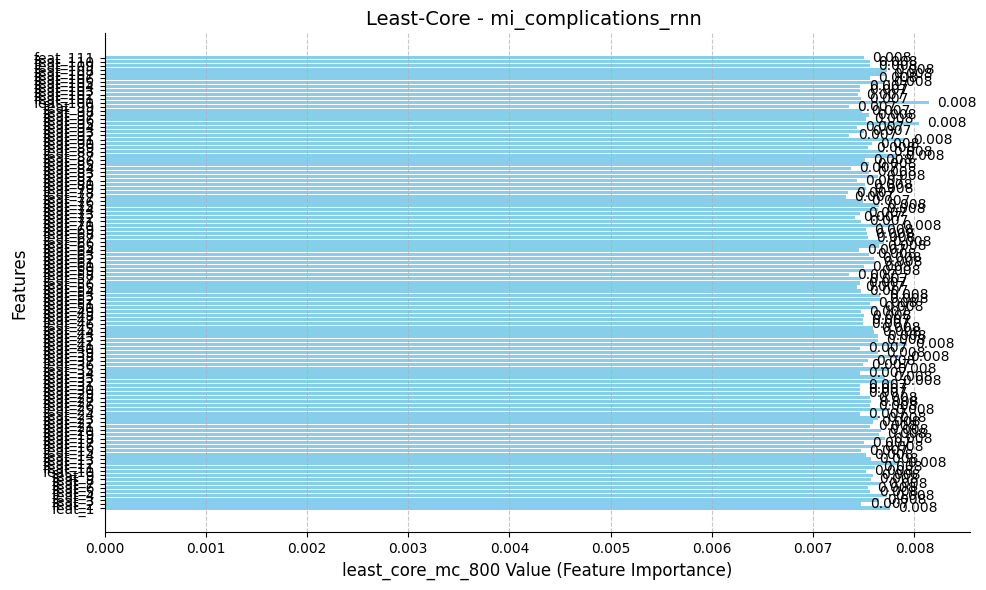

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import logging
import sys, os

# Make project imports work (find the project root)
from pathlib import Path as _Path

HERE = _Path.cwd().resolve()
root = None
for p in [HERE] + list(HERE.parents):
    if (p / "cgt_xai").is_dir():
        root = p
        break
if root is None:
    raise RuntimeError(f"Could not find project root containing 'cgt_xai' from {HERE}")

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

print("Project root added to sys.path:", root)

# Imports
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from scipy.stats import spearmanr, pearsonr

from cgt_xai.models import get_model
from cgt_xai.utils.plotting import plot_single_valuation

import cvxpy as cp

# Logging
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

# Config
DATASETS = ["mi_complications"]
MODEL_NAMES = ["rnn"]
RANDOM_STATE = 42

# Utility for least-core (continuous is best)
UTILITY_MODE = "accuracy"     # "neg_logprob" or "accuracy"
BASELINE_MODE = "mean"           # "mean" or "median" for masking

# Least-core settings (START SMALL; increase later)
LEAST_CORE_MC_ITERS = 800        # try 800 first; then 1500; then 3000
LEAST_CORE_EPSILON = 1e-3

# Solver options
LEAST_CORE_SOLVER_OPTS = {
    "solver": "SCS",
    "max_iters": 20000,
    "eps": 1e-4,
    "verbose": False
}

# Constraints stabilization
ENSURE_SINGLETONS = True
INCLUDE_COMPLEMENTS = True
ADD_BOX_BOUNDS = True

NOISE_LEVEL = 0.05

# Output
BASE_OUTPUT_DIR = Path("./output/feature_valuation_uci")
BASE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Dataset loaders
def load_mi_complications(binary_let_is=True):
    path = "../../datasets/MI.data"
    df = pd.read_csv(path, header=None, na_values="?")

    X_df = df.iloc[:, 1:112]
    feature_names = [f"feat_{i}" for i in range(1, X_df.shape[1] + 1)]

    let_is = df.iloc[:, 123].astype(int).values
    y = (let_is != 0).astype(int) if binary_let_is else let_is

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df).astype(np.float32)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_dataset(name: str):
    if name == "mi_complications":
        return load_mi_complications(binary_let_is=True)
    raise ValueError(f"Unknown dataset name: {name}")

# Utility helpers (FAST: train once, mask features)
class DataWrapper:
    def __init__(self, indices, names=None):
        self.indices = indices
        self.data_names = names if names is not None else [f"f{i}" for i in range(len(indices))]

    def __len__(self):
        return len(self.indices)

    def __iter__(self):
        return iter(self.indices)


def _safe_logprob_score(model, X, y):
    eps = 1e-12
    proba = model.predict_proba(X)
    classes = model.classes_
    cls_to_i = {c: i for i, c in enumerate(classes)}
    y_idx = np.array([cls_to_i[yy] for yy in y], dtype=int)
    p = proba[np.arange(len(y)), y_idx]
    return float(np.mean(np.log(np.clip(p, eps, 1.0))))


class FixedModelMaskedUtility:
    """
    Train ONE model on all features.
    Define v(S) by masking features not in S to a baseline (mean/median) and
    evaluating on test set (no retraining per subset).
    """

    def __init__(
        self,
        X_train, y_train, X_test, y_test,
        model_name: str,
        feature_names=None,
        random_state: int = 42,
        utility_mode: str = "neg_logprob",
        baseline: str = "mean",
        force_cpu_for_rnn: bool = True,
    ):
        self.X_train = np.asarray(X_train, dtype=np.float32)
        self.y_train = np.asarray(y_train)
        self.X_test = np.asarray(X_test, dtype=np.float32)
        self.y_test = np.asarray(y_test)

        self.model_name = model_name
        self.random_state = int(random_state)
        self.utility_mode = utility_mode

        self.data = DataWrapper(list(range(self.X_train.shape[1])), feature_names)

        if baseline == "mean":
            self._base = self.X_train.mean(axis=0, keepdims=True)
        elif baseline == "median":
            self._base = np.median(self.X_train, axis=0, keepdims=True).astype(np.float32)
        else:
            raise ValueError("baseline must be 'mean' or 'median'")

        # Train once
        self.model = get_model(model_name, self.random_state)

        if model_name.lower() == "rnn" and force_cpu_for_rnn:
            if hasattr(self.model, "device"):
                self.model.device = "cpu"

        self.model.fit(self.X_train, self.y_train)
        self._cache = {}

    def _mask_X(self, X: np.ndarray, subset_key: tuple) -> np.ndarray:
        X = np.asarray(X, dtype=np.float32)
        Xm = np.repeat(self._base, X.shape[0], axis=0)  # baseline everywhere
        if len(subset_key) > 0:
            Xm[:, subset_key] = X[:, subset_key]
        return Xm

    def __call__(self, subset):
        subset_key = tuple(sorted(subset))
        if subset_key in self._cache:
            return self._cache[subset_key]

        X_masked = self._mask_X(self.X_test, subset_key)

        if self.utility_mode == "neg_logprob":
            if not hasattr(self.model, "predict_proba"):
                raise RuntimeError("neg_logprob requires predict_proba()")
            val = _safe_logprob_score(self.model, X_masked, self.y_test)

        elif self.utility_mode == "accuracy":
            y_pred = self.model.predict(X_masked)
            val = float(accuracy_score(self.y_test, y_pred))

        else:
            raise ValueError("UTILITY_MODE must be 'neg_logprob' or 'accuracy'")

        self._cache[subset_key] = float(val)
        return float(val)

class ValuationResult:
    def __init__(self, algorithm, status, values, subsidy, stderr, data_names):
        self.algorithm = algorithm
        self.status = status
        self.values = values
        self.subsidy = subsidy
        self.stderr = stderr
        self.data_names = data_names


def _to_solver(solver_opt):
    if solver_opt is None:
        return None
    if isinstance(solver_opt, str):
        s = solver_opt.upper()
        if hasattr(cp, s):
            return getattr(cp, s)
        return solver_opt
    return solver_opt


def _solve_least_core_lp(A_eq, b_eq, A_lb, b_lb, epsilon=0.0,
                         add_box_bounds=True, box_M=None, **options):
    A_eq = np.asarray(A_eq, dtype=float)
    b_eq = np.asarray(b_eq, dtype=float).reshape(-1)
    A_lb = np.asarray(A_lb, dtype=float)
    b_lb = np.asarray(b_lb, dtype=float).reshape(-1)

    n = A_eq.shape[1]
    x = cp.Variable(n)
    subsidy = cp.Variable()

    cons = [
        A_eq @ x == b_eq,
        A_lb @ x + subsidy >= b_lb - float(epsilon),
    ]

    if add_box_bounds:
        if box_M is None:
            vmax = float(np.max(np.abs(b_lb))) if b_lb.size else 1.0
            vN = float(np.max(np.abs(b_eq))) if b_eq.size else 1.0
            box_M = 50.0 * max(1.0, vmax, vN)
        cons += [x <= box_M, x >= -box_M]

    prob = cp.Problem(cp.Minimize(subsidy), cons)

    if "solver" in options:
        options["solver"] = _to_solver(options["solver"])

    try:
        prob.solve(**options)
    except Exception as e:
        return None, None, f"exception:{e}"

    status = str(prob.status)
    if status not in ("optimal", "optimal_inaccurate"):
        return None, None, status

    return np.array(x.value, dtype=float), float(subsidy.value), status


def montecarlo_least_core_local(
    utility,
    n_iterations: int,
    epsilon: float = 0.0,
    options=None,
    ensure_singletons: bool = True,
    include_complements: bool = True,
    add_box_bounds: bool = True,
    box_M=None,
    rng_seed: int = 42
):
    if options is None:
        options = {}

    n = len(utility.data)
    rng = np.random.default_rng(rng_seed)

    coalitions = set()

    if ensure_singletons:
        for i in range(n):
            coalitions.add((i,))

    for _ in range(int(n_iterations)):
        k = int(rng.integers(1, n))   # 1..n-1
        subset = tuple(sorted(rng.choice(n, k, replace=False).tolist()))
        coalitions.add(subset)

        if include_complements:
            comp = tuple(sorted(set(range(n)) - set(subset)))
            if 0 < len(comp) < n:
                coalitions.add(comp)

    coalitions = list(coalitions)
    A_lb = np.zeros((len(coalitions), n), dtype=float)
    b_lb = np.zeros(len(coalitions), dtype=float)

    for r, subset in enumerate(coalitions):
        subset = list(subset)
        A_lb[r, subset] = 1.0
        b_lb[r] = float(utility(subset))

    vN = float(utility(list(range(n))))

    values, subsidy, status = _solve_least_core_lp(
        A_eq=np.ones((1, n), dtype=float),
        b_eq=np.array([vN], dtype=float),
        A_lb=A_lb,
        b_lb=b_lb,
        epsilon=float(epsilon),
        add_box_bounds=add_box_bounds,
        box_M=box_M,
        **options
    )

    if values is None:
        raise RuntimeError(
            f"montecarlo_least_core failed: status={status}. "
            f"Try ECOS if installed or increase max_iters."
        )

    return ValuationResult("montecarlo_least_core", status, values, subsidy, None, utility.data.data_names)


def compute_least_core(utility, n_features):
    res = montecarlo_least_core_local(
        utility,
        n_iterations=LEAST_CORE_MC_ITERS,
        epsilon=LEAST_CORE_EPSILON,
        options=LEAST_CORE_SOLVER_OPTS,
        ensure_singletons=ENSURE_SINGLETONS,
        include_complements=INCLUDE_COMPLEMENTS,
        add_box_bounds=ADD_BOX_BOUNDS,
        box_M=None,
        rng_seed=RANDOM_STATE
    )
    return f"least_core_mc_{LEAST_CORE_MC_ITERS}", np.array(res.values, dtype=float), getattr(res, "subsidy", None)

# Faithfulness + Robustness metrics
def _cosine(a, b, eps=1e-12):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    return float(np.dot(a, b) / ((np.linalg.norm(a) * np.linalg.norm(b)) + eps))

def compute_metrics(method_tag, phi, utility, n_features, X_train, y_train, X_test, y_test,
                    feature_names, model_name, output_dir):
    """
    Computes:
      - Faithfulness(Spearman), Alignment(Pearson), Cosine(phi, LOO)
      - Robustness under test-time noise: cosine(phi, phi_noisy), rank corr, L2
    """
    all_features = list(range(n_features))
    vN = float(utility(all_features))

    loo = np.zeros(n_features, dtype=float)
    for i in range(n_features):
        subset_minus_i = [j for j in all_features if j != i]
        loo[i] = vN - float(utility(subset_minus_i))

    spearman_corr, spearman_p = spearmanr(phi, loo)
    pearson_corr, pearson_p = pearsonr(phi, loo)
    cos_loo = _cosine(phi, loo)

    faith_df = pd.DataFrame([{
        "method": method_tag,
        "faithfulness_spearman": spearman_corr,
        "p_value_spearman": spearman_p,
        "predictive_alignment_pearson": pearson_corr,
        "p_value_pearson": pearson_p,
        "attribution_cosine_vs_loo": cos_loo
    }])

    faith_csv = output_dir / f"faithfulness_{method_tag}.csv"
    faith_df.to_csv(faith_csv, index=False)

    X_test = np.asarray(X_test, dtype=np.float32)
    std = np.std(X_test, axis=0, keepdims=True).astype(np.float32) + 1e-6
    noise = np.random.normal(0, NOISE_LEVEL * std, size=X_test.shape).astype(np.float32)
    X_test_noisy = (X_test + noise).astype(np.float32)

    utility_noisy = FixedModelMaskedUtility(
        X_train, y_train, X_test_noisy, y_test,
        model_name=model_name,
        feature_names=feature_names,
        random_state=RANDOM_STATE,
        utility_mode=UTILITY_MODE,
        baseline=BASELINE_MODE,
        force_cpu_for_rnn=True
    )

    _, phi_noisy, _ = compute_least_core(utility_noisy, n_features)
    phi_noisy = np.asarray(phi_noisy, dtype=float)

    rob_cos = _cosine(phi, phi_noisy)
    rank_corr, rank_p = spearmanr(phi, phi_noisy)
    l2 = float(np.linalg.norm(phi - phi_noisy))
    l2_norm = float(l2 / (np.linalg.norm(phi) + 1e-12))

    rob_df = pd.DataFrame([{
        "method": method_tag,
        "robustness_cosine": rob_cos,
        "rank_robustness_spearman": rank_corr,
        "p_value_rank_robustness": rank_p,
        "l2": l2,
        "normalized_l2": l2_norm
    }])

    rob_csv = output_dir / f"robustness_{method_tag}.csv"
    rob_df.to_csv(rob_csv, index=False)

    logger.info("\nFAITHFULNESS METRICS")
    logger.info(f"  Faithfulness(Spearman ↑)      = {spearman_corr:.4f} (p={spearman_p:.2e})")
    logger.info(f"  Predictive Alignment(Pearson↑)= {pearson_corr:.4f} (p={pearson_p:.2e})")
    logger.info(f"  Attribution Cosine ↑          = {cos_loo:.4f}")
    logger.info(f"  Saved: {faith_csv}")

    logger.info("\nROBUSTNESS METRICS")
    logger.info(f"  Robustness Cosine ↑           = {rob_cos:.4f}")
    logger.info(f"  Rank Robustness ↑             = {rank_corr:.4f} (p={rank_p:.2e})")
    logger.info(f"  L2 ↓                          = {l2:.6f}")
    logger.info(f"  Normalized L2 ↓               = {l2_norm:.6f}")
    logger.info(f"  Saved: {rob_csv}")

# Main
def main():
    for dataset_name in DATASETS:
        X_train, X_test, y_train, y_test, feature_names = load_dataset(dataset_name)

        for model_name in MODEL_NAMES:
            logger.info("\n" + "=" * 70)
            logger.info(f"DATASET: {dataset_name} | MODEL: {model_name}")
            logger.info("=" * 70)

            OUTPUT_DIR = BASE_OUTPUT_DIR / f"{dataset_name}_{model_name}_results"
            OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

            utility = FixedModelMaskedUtility(
                X_train, y_train, X_test, y_test,
                model_name=model_name,
                feature_names=feature_names,
                random_state=RANDOM_STATE,
                utility_mode=UTILITY_MODE,
                baseline=BASELINE_MODE,
                force_cpu_for_rnn=True
            )

            n_features = X_train.shape[1]
            v_N = utility(list(range(n_features)))
            logger.info(f"  v(N) (UTILITY_MODE={UTILITY_MODE}, masked) = {v_N:.6f}")

            logger.info("Computing Least-Core values (FAST masked utility)...")
            method_tag, lc_vals, lc_subsidy = compute_least_core(utility, n_features)

            if lc_subsidy is None:
                logger.info("  Least-core subsidy = None")
            else:
                logger.info(f"  Least-core subsidy = {float(lc_subsidy):.6f}")

            df_vals = pd.DataFrame({"method": method_tag, "feature": feature_names, "value": lc_vals})
            vals_csv_path = OUTPUT_DIR / f"{dataset_name}_{model_name}_feature_valuations_{method_tag}.csv"
            df_vals.to_csv(vals_csv_path, index=False)
            logger.info(f"  Saved least-core valuations to: {vals_csv_path}")

            # Plot
            try:
                plot_single_valuation(
                    lc_vals, feature_names,
                    method_name=method_tag,
                    title=f"Least-Core - {dataset_name}_{model_name} ",
                    output_path=OUTPUT_DIR / f"{dataset_name}_{model_name}_{method_tag}.png"
                )
            except Exception as e:
                logger.warning(f"Plot failed: {e}")

            phi = np.asarray(lc_vals, dtype=float)
            compute_metrics(
                method_tag=method_tag,
                phi=phi,
                utility=utility,
                n_features=n_features,
                X_train=X_train,
                y_train=y_train,
                X_test=X_test,
                y_test=y_test,
                feature_names=feature_names,
                model_name=model_name,
                output_dir=OUTPUT_DIR
            )

            logger.info(f"\nDone. Saved outputs to: {OUTPUT_DIR}")
            logger.info("=" * 70)

if __name__ == "__main__":
    main()

✅ Project root added to sys.path: 


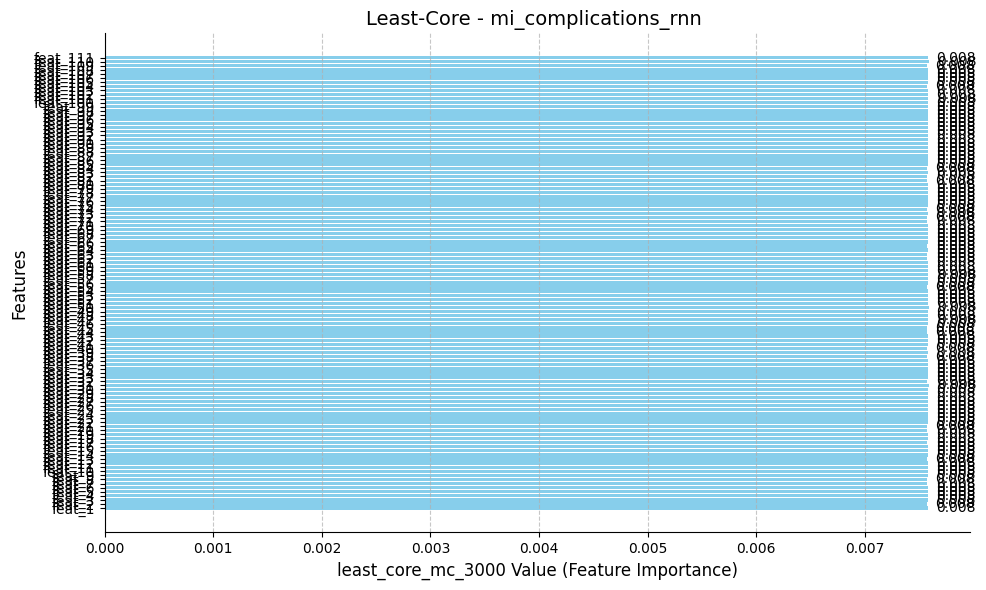

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import logging
import sys, os

# Make project imports work (find the project root)
from pathlib import Path as _Path

HERE = _Path.cwd().resolve()
root = None
for p in [HERE] + list(HERE.parents):
    if (p / "cgt_xai").is_dir():
        root = p
        break
if root is None:
    raise RuntimeError(f"Could not find project root containing 'cgt_xai' from {HERE}")

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

print("Project root added to sys.path:", root)

# Imports
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from scipy.stats import spearmanr, pearsonr

from cgt_xai.models import get_model
from cgt_xai.utils.plotting import plot_single_valuation

import cvxpy as cp

# Logging
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

# Config
DATASETS = ["mi_complications"]
MODEL_NAMES = ["rnn"]
RANDOM_STATE = 42

# Utility for least-core (continuous is best)
UTILITY_MODE = "accuracy"     # "neg_logprob" or "accuracy"
BASELINE_MODE = "mean"           # "mean" or "median" for masking

# Least-core settings (START SMALL; increase later)
LEAST_CORE_MC_ITERS = 3000        # try 800 first; then 1500; then 3000
LEAST_CORE_EPSILON = 1e-3

# Solver options
LEAST_CORE_SOLVER_OPTS = {
    "solver": "SCS",
    "max_iters": 20000,
    "eps": 1e-4,
    "verbose": False
}

# Constraints stabilization
ENSURE_SINGLETONS = True
INCLUDE_COMPLEMENTS = True
ADD_BOX_BOUNDS = True

NOISE_LEVEL = 0.05

# Output
BASE_OUTPUT_DIR = Path("./output/feature_valuation_uci")
BASE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Dataset loaders
def load_mi_complications(binary_let_is=True):
    path = "../../datasets/MI.data"
    df = pd.read_csv(path, header=None, na_values="?")

    X_df = df.iloc[:, 1:112]
    feature_names = [f"feat_{i}" for i in range(1, X_df.shape[1] + 1)]

    let_is = df.iloc[:, 123].astype(int).values
    y = (let_is != 0).astype(int) if binary_let_is else let_is

    imputer = SimpleImputer(strategy="most_frequent")
    X = imputer.fit_transform(X_df).astype(np.float32)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
    )
    return X_train, X_test, y_train, y_test, feature_names


def load_dataset(name: str):
    if name == "mi_complications":
        return load_mi_complications(binary_let_is=True)
    raise ValueError(f"Unknown dataset name: {name}")

# Utility helpers (FAST: train once, mask features)
class DataWrapper:
    def __init__(self, indices, names=None):
        self.indices = indices
        self.data_names = names if names is not None else [f"f{i}" for i in range(len(indices))]

    def __len__(self):
        return len(self.indices)

    def __iter__(self):
        return iter(self.indices)


def _safe_logprob_score(model, X, y):
    eps = 1e-12
    proba = model.predict_proba(X)
    classes = model.classes_
    cls_to_i = {c: i for i, c in enumerate(classes)}
    y_idx = np.array([cls_to_i[yy] for yy in y], dtype=int)
    p = proba[np.arange(len(y)), y_idx]
    return float(np.mean(np.log(np.clip(p, eps, 1.0))))


class FixedModelMaskedUtility:
    """
    Train ONE model on all features.
    Define v(S) by masking features not in S to a baseline (mean/median) and
    evaluating on test set (no retraining per subset).
    """

    def __init__(
        self,
        X_train, y_train, X_test, y_test,
        model_name: str,
        feature_names=None,
        random_state: int = 42,
        utility_mode: str = "neg_logprob",
        baseline: str = "mean",
        force_cpu_for_rnn: bool = True,
    ):
        self.X_train = np.asarray(X_train, dtype=np.float32)
        self.y_train = np.asarray(y_train)
        self.X_test = np.asarray(X_test, dtype=np.float32)
        self.y_test = np.asarray(y_test)

        self.model_name = model_name
        self.random_state = int(random_state)
        self.utility_mode = utility_mode

        self.data = DataWrapper(list(range(self.X_train.shape[1])), feature_names)

        if baseline == "mean":
            self._base = self.X_train.mean(axis=0, keepdims=True)
        elif baseline == "median":
            self._base = np.median(self.X_train, axis=0, keepdims=True).astype(np.float32)
        else:
            raise ValueError("baseline must be 'mean' or 'median'")

        # Train once
        self.model = get_model(model_name, self.random_state)

        if model_name.lower() == "rnn" and force_cpu_for_rnn:
            if hasattr(self.model, "device"):
                self.model.device = "cpu"

        self.model.fit(self.X_train, self.y_train)
        self._cache = {}

    def _mask_X(self, X: np.ndarray, subset_key: tuple) -> np.ndarray:
        X = np.asarray(X, dtype=np.float32)
        Xm = np.repeat(self._base, X.shape[0], axis=0)  # baseline everywhere
        if len(subset_key) > 0:
            Xm[:, subset_key] = X[:, subset_key]
        return Xm

    def __call__(self, subset):
        subset_key = tuple(sorted(subset))
        if subset_key in self._cache:
            return self._cache[subset_key]

        X_masked = self._mask_X(self.X_test, subset_key)

        if self.utility_mode == "neg_logprob":
            if not hasattr(self.model, "predict_proba"):
                raise RuntimeError("neg_logprob requires predict_proba()")
            val = _safe_logprob_score(self.model, X_masked, self.y_test)

        elif self.utility_mode == "accuracy":
            y_pred = self.model.predict(X_masked)
            val = float(accuracy_score(self.y_test, y_pred))

        else:
            raise ValueError("UTILITY_MODE must be 'neg_logprob' or 'accuracy'")

        self._cache[subset_key] = float(val)
        return float(val)

class ValuationResult:
    def __init__(self, algorithm, status, values, subsidy, stderr, data_names):
        self.algorithm = algorithm
        self.status = status
        self.values = values
        self.subsidy = subsidy
        self.stderr = stderr
        self.data_names = data_names


def _to_solver(solver_opt):
    if solver_opt is None:
        return None
    if isinstance(solver_opt, str):
        s = solver_opt.upper()
        if hasattr(cp, s):
            return getattr(cp, s)
        return solver_opt
    return solver_opt


def _solve_least_core_lp(A_eq, b_eq, A_lb, b_lb, epsilon=0.0,
                         add_box_bounds=True, box_M=None, **options):
    A_eq = np.asarray(A_eq, dtype=float)
    b_eq = np.asarray(b_eq, dtype=float).reshape(-1)
    A_lb = np.asarray(A_lb, dtype=float)
    b_lb = np.asarray(b_lb, dtype=float).reshape(-1)

    n = A_eq.shape[1]
    x = cp.Variable(n)
    subsidy = cp.Variable()

    cons = [
        A_eq @ x == b_eq,
        A_lb @ x + subsidy >= b_lb - float(epsilon),
    ]

    if add_box_bounds:
        if box_M is None:
            vmax = float(np.max(np.abs(b_lb))) if b_lb.size else 1.0
            vN = float(np.max(np.abs(b_eq))) if b_eq.size else 1.0
            box_M = 50.0 * max(1.0, vmax, vN)
        cons += [x <= box_M, x >= -box_M]

    prob = cp.Problem(cp.Minimize(subsidy), cons)

    if "solver" in options:
        options["solver"] = _to_solver(options["solver"])

    try:
        prob.solve(**options)
    except Exception as e:
        return None, None, f"exception:{e}"

    status = str(prob.status)
    if status not in ("optimal", "optimal_inaccurate"):
        return None, None, status

    return np.array(x.value, dtype=float), float(subsidy.value), status


def montecarlo_least_core_local(
    utility,
    n_iterations: int,
    epsilon: float = 0.0,
    options=None,
    ensure_singletons: bool = True,
    include_complements: bool = True,
    add_box_bounds: bool = True,
    box_M=None,
    rng_seed: int = 42
):
    if options is None:
        options = {}

    n = len(utility.data)
    rng = np.random.default_rng(rng_seed)

    coalitions = set()

    if ensure_singletons:
        for i in range(n):
            coalitions.add((i,))

    for _ in range(int(n_iterations)):
        k = int(rng.integers(1, n))   # 1..n-1
        subset = tuple(sorted(rng.choice(n, k, replace=False).tolist()))
        coalitions.add(subset)

        if include_complements:
            comp = tuple(sorted(set(range(n)) - set(subset)))
            if 0 < len(comp) < n:
                coalitions.add(comp)

    coalitions = list(coalitions)
    A_lb = np.zeros((len(coalitions), n), dtype=float)
    b_lb = np.zeros(len(coalitions), dtype=float)

    for r, subset in enumerate(coalitions):
        subset = list(subset)
        A_lb[r, subset] = 1.0
        b_lb[r] = float(utility(subset))

    vN = float(utility(list(range(n))))

    values, subsidy, status = _solve_least_core_lp(
        A_eq=np.ones((1, n), dtype=float),
        b_eq=np.array([vN], dtype=float),
        A_lb=A_lb,
        b_lb=b_lb,
        epsilon=float(epsilon),
        add_box_bounds=add_box_bounds,
        box_M=box_M,
        **options
    )

    if values is None:
        raise RuntimeError(
            f"montecarlo_least_core failed: status={status}. "
            f"Try ECOS if installed or increase max_iters."
        )

    return ValuationResult("montecarlo_least_core", status, values, subsidy, None, utility.data.data_names)


def compute_least_core(utility, n_features):
    res = montecarlo_least_core_local(
        utility,
        n_iterations=LEAST_CORE_MC_ITERS,
        epsilon=LEAST_CORE_EPSILON,
        options=LEAST_CORE_SOLVER_OPTS,
        ensure_singletons=ENSURE_SINGLETONS,
        include_complements=INCLUDE_COMPLEMENTS,
        add_box_bounds=ADD_BOX_BOUNDS,
        box_M=None,
        rng_seed=RANDOM_STATE
    )
    return f"least_core_mc_{LEAST_CORE_MC_ITERS}", np.array(res.values, dtype=float), getattr(res, "subsidy", None)

# Faithfulness + Robustness metrics
def _cosine(a, b, eps=1e-12):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    return float(np.dot(a, b) / ((np.linalg.norm(a) * np.linalg.norm(b)) + eps))

def compute_metrics(method_tag, phi, utility, n_features, X_train, y_train, X_test, y_test,
                    feature_names, model_name, output_dir):
    """
    Computes:
      - Faithfulness(Spearman), Alignment(Pearson), Cosine(phi, LOO)
      - Robustness under test-time noise: cosine(phi, phi_noisy), rank corr, L2
    """
    all_features = list(range(n_features))
    vN = float(utility(all_features))

    loo = np.zeros(n_features, dtype=float)
    for i in range(n_features):
        subset_minus_i = [j for j in all_features if j != i]
        loo[i] = vN - float(utility(subset_minus_i))

    spearman_corr, spearman_p = spearmanr(phi, loo)
    pearson_corr, pearson_p = pearsonr(phi, loo)
    cos_loo = _cosine(phi, loo)

    faith_df = pd.DataFrame([{
        "method": method_tag,
        "faithfulness_spearman": spearman_corr,
        "p_value_spearman": spearman_p,
        "predictive_alignment_pearson": pearson_corr,
        "p_value_pearson": pearson_p,
        "attribution_cosine_vs_loo": cos_loo
    }])

    faith_csv = output_dir / f"faithfulness_{method_tag}.csv"
    faith_df.to_csv(faith_csv, index=False)

    X_test = np.asarray(X_test, dtype=np.float32)
    std = np.std(X_test, axis=0, keepdims=True).astype(np.float32) + 1e-6
    noise = np.random.normal(0, NOISE_LEVEL * std, size=X_test.shape).astype(np.float32)
    X_test_noisy = (X_test + noise).astype(np.float32)

    utility_noisy = FixedModelMaskedUtility(
        X_train, y_train, X_test_noisy, y_test,
        model_name=model_name,
        feature_names=feature_names,
        random_state=RANDOM_STATE,
        utility_mode=UTILITY_MODE,
        baseline=BASELINE_MODE,
        force_cpu_for_rnn=True
    )

    _, phi_noisy, _ = compute_least_core(utility_noisy, n_features)
    phi_noisy = np.asarray(phi_noisy, dtype=float)

    rob_cos = _cosine(phi, phi_noisy)
    rank_corr, rank_p = spearmanr(phi, phi_noisy)
    l2 = float(np.linalg.norm(phi - phi_noisy))
    l2_norm = float(l2 / (np.linalg.norm(phi) + 1e-12))

    rob_df = pd.DataFrame([{
        "method": method_tag,
        "robustness_cosine": rob_cos,
        "rank_robustness_spearman": rank_corr,
        "p_value_rank_robustness": rank_p,
        "l2": l2,
        "normalized_l2": l2_norm
    }])

    rob_csv = output_dir / f"robustness_{method_tag}.csv"
    rob_df.to_csv(rob_csv, index=False)

    logger.info("\nFAITHFULNESS METRICS")
    logger.info(f"  Faithfulness(Spearman ↑)      = {spearman_corr:.4f} (p={spearman_p:.2e})")
    logger.info(f"  Predictive Alignment(Pearson↑)= {pearson_corr:.4f} (p={pearson_p:.2e})")
    logger.info(f"  Attribution Cosine ↑          = {cos_loo:.4f}")
    logger.info(f"  Saved: {faith_csv}")

    logger.info("\nROBUSTNESS METRICS")
    logger.info(f"  Robustness Cosine ↑           = {rob_cos:.4f}")
    logger.info(f"  Rank Robustness ↑             = {rank_corr:.4f} (p={rank_p:.2e})")
    logger.info(f"  L2 ↓                          = {l2:.6f}")
    logger.info(f"  Normalized L2 ↓               = {l2_norm:.6f}")
    logger.info(f"  Saved: {rob_csv}")

# Main
def main():
    for dataset_name in DATASETS:
        X_train, X_test, y_train, y_test, feature_names = load_dataset(dataset_name)

        for model_name in MODEL_NAMES:
            logger.info("\n" + "=" * 70)
            logger.info(f"DATASET: {dataset_name} | MODEL: {model_name}")
            logger.info("=" * 70)

            OUTPUT_DIR = BASE_OUTPUT_DIR / f"{dataset_name}_{model_name}_results"
            OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

            utility = FixedModelMaskedUtility(
                X_train, y_train, X_test, y_test,
                model_name=model_name,
                feature_names=feature_names,
                random_state=RANDOM_STATE,
                utility_mode=UTILITY_MODE,
                baseline=BASELINE_MODE,
                force_cpu_for_rnn=True
            )

            n_features = X_train.shape[1]
            v_N = utility(list(range(n_features)))
            logger.info(f"  v(N) (UTILITY_MODE={UTILITY_MODE}, masked) = {v_N:.6f}")

            logger.info("Computing Least-Core values (FAST masked utility)...")
            method_tag, lc_vals, lc_subsidy = compute_least_core(utility, n_features)

            if lc_subsidy is None:
                logger.info("  Least-core subsidy = None")
            else:
                logger.info(f"  Least-core subsidy = {float(lc_subsidy):.6f}")

            df_vals = pd.DataFrame({"method": method_tag, "feature": feature_names, "value": lc_vals})
            vals_csv_path = OUTPUT_DIR / f"{dataset_name}_{model_name}_feature_valuations_{method_tag}.csv"
            df_vals.to_csv(vals_csv_path, index=False)
            logger.info(f"  Saved least-core valuations to: {vals_csv_path}")

            # Plot
            try:
                plot_single_valuation(
                    lc_vals, feature_names,
                    method_name=method_tag,
                    title=f"Least-Core - {dataset_name}_{model_name} ",
                    output_path=OUTPUT_DIR / f"{dataset_name}_{model_name}_{method_tag}.png"
                )
            except Exception as e:
                logger.warning(f"Plot failed: {e}")

            phi = np.asarray(lc_vals, dtype=float)
            compute_metrics(
                method_tag=method_tag,
                phi=phi,
                utility=utility,
                n_features=n_features,
                X_train=X_train,
                y_train=y_train,
                X_test=X_test,
                y_test=y_test,
                feature_names=feature_names,
                model_name=model_name,
                output_dir=OUTPUT_DIR
            )

            logger.info(f"\nDone. Saved outputs to: {OUTPUT_DIR}")
            logger.info("=" * 70)

if __name__ == "__main__":
    main()